<a href="https://colab.research.google.com/github/semyannovavlada-wq/LabWorkForITMO/blob/main/Lab01_temperature.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab01 - sprint 1
**Датасет:** CalCOFI (океанографические измерения)
**Моя случайная величина:** температура воды `T_degC`, °C

## Random Variable 01 — температура воды (`T_degC`)

### Description (природа события)

Датасет CalCOFI — это результаты многолетних океанографических экспедиций у берегов Калифорнии. Корабль приходит на станцию, опускает в воду батометры (бутылки для отбора воды) на разные глубины и измеряет параметры воды: температуру, солёность, кислород и т. д.

Одна строка таблицы = одна «бутылка» = один отбор воды на конкретной глубине, на конкретной станции, в конкретное время.

Температура воды `T_degC` измеряется в градусах Цельсия. Она зависит от очень многих факторов: сезона, времени суток, течений, погоды, глубины, района, вихрей, явлений типа Эль-Ниньо, плюс есть ошибка самого прибора. Все эти факторы учесть и записать одной формулой невозможно, поэтому *заранее* точное значение температуры мы не знаем, мы можем только измерить его. Это и есть случайная величина.

**Тип величины:** непрерывная (температура может принимать любое значение на отрезке).

### Setup

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.titlesize"] = 13

SEED = 42
rng = np.random.default_rng(SEED)

In [22]:
import kagglehub
path = kagglehub.dataset_download("sohier/calcofi")
DATA_PATH = path + "/bottle.csv"
df = pd.read_csv(DATA_PATH, usecols=["Sta_ID", "Depthm", "T_degC", "Salnty"],
                 encoding="latin-1", low_memory=False)
print("Размер таблицы:", df.shape)
df.head()

Using Colab cache for faster access to the 'calcofi' dataset.
Размер таблицы: (864863, 4)


,Sta_ID,Depthm,T_degC,Salnty
0,054.0 056.0,0,10.50,33.440
1,054.0 056.0,8,10.46,33.440
2,054.0 056.0,10,10.46,33.437
3,054.0 056.0,19,10.45,33.420
4,054.0 056.0,20,10.45,33.421


In [23]:
print("Пропуски в каждой колонке:")
print(df.isna().sum())
temp = df["T_degC"].dropna().reset_index(drop=True)
N = len(temp)
print(f"\nN (размер генеральной совокупности) = {N}")

Пропуски в каждой колонке:
Sta_ID        0
Depthm        0
T_degC    10963
Salnty    47354
dtype: int64

N (размер генеральной совокупности) = 853900


Пропуски в температуре просто выкидываем: они возникают, когда прибор не записал значение, и заполнять их выдуманными числами было бы неправильно. Остальные измерения оставляем как есть, ничего не удаляем «на глаз».

**Генеральная совокупность** в этой работе — все `N` измерений температуры из файла.

### Proof of randomness (почему это случайная величина)

Идея доказательства: если бы температуру можно было посчитать по формуле, то при одинаковых «входных параметрах» мы получали бы одинаковый результат. Главный и самый очевидный параметр, от которого зависит температура, — глубина. Возьмём срез на одной глубине (поверхность, `Depthm = 0`) и посмотрим, будет ли температура одинаковой.

Измерений на глубине 0 м: 32344
Количество разных значений температуры: 2873
Минимум: 8.36 °C, максимум: 31.14 °C
Среднее: 16.47 °C, стд. отклонение: 2.94 °C


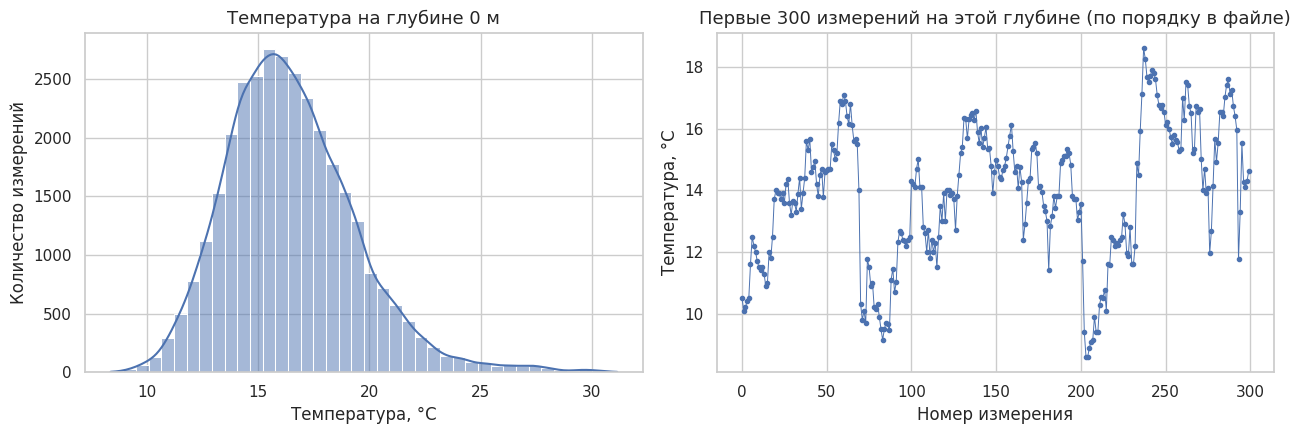

In [24]:
DEPTH = 0
surface = df.loc[df["Depthm"] == DEPTH, "T_degC"].dropna()

print(f"Измерений на глубине {DEPTH} м: {len(surface)}")
print(f"Количество разных значений температуры: {surface.nunique()}")
print(f"Минимум: {surface.min():.2f} °C, максимум: {surface.max():.2f} °C")
print(f"Среднее: {surface.mean():.2f} °C, стд. отклонение: {surface.std():.2f} °C")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(surface, bins=40, kde=True, ax=ax[0])
ax[0].set_title(f"Температура на глубине {DEPTH} м")
ax[0].set_xlabel("Температура, °C"); ax[0].set_ylabel("Количество измерений")

ax[1].plot(surface.values[:300], marker=".", lw=0.7)
ax[1].set_title("Первые 300 измерений на этой глубине (по порядку в файле)")
ax[1].set_xlabel("Номер измерения"); ax[1].set_ylabel("Температура, °C")
plt.tight_layout(); plt.show()

Глубина одна и та же, а температура разная — разброс заметный. Значит, глубина не определяет температуру однозначно.

Проверим то же самое ещё одним способом: попробуем *построить формулу* $T = f(\text{depth})$ и посмотрим, какую долю разброса она объясняет. Для этого приблизим зависимость полиномом 5-й степени от $\ln(1+\text{depth})$ и посчитаем коэффициент детерминации $R^2$:

$$R^2 = 1 - \frac{\sum_i (T_i - \hat T_i)^2}{\sum_i (T_i - \bar T)^2}$$

Если бы температура считалась по формуле, $R^2$ было бы равно 1.

R^2 модели 'температура = f(глубина)': 0.782
Стд. отклонение остатков: 1.98 °C


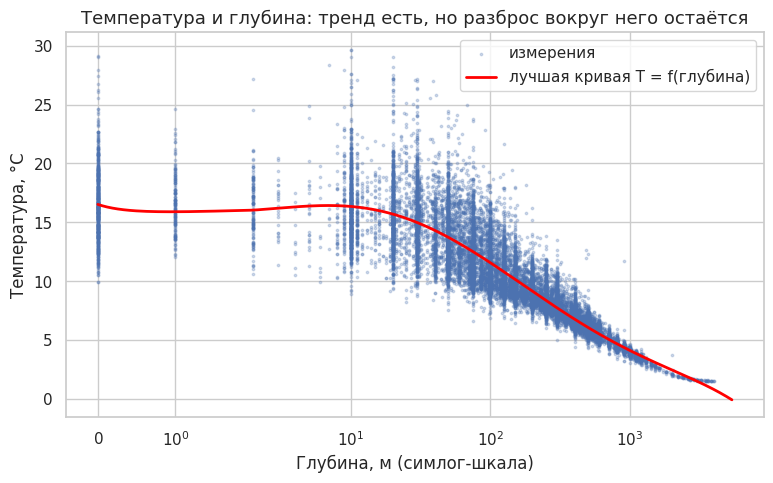

In [25]:
sub = df[["Depthm", "T_degC"]].dropna()
x = np.log1p(sub["Depthm"].values)
y = sub["T_degC"].values

coef = np.polyfit(x, y, deg=5)
y_hat = np.polyval(coef, x)
r2 = 1 - np.sum((y - y_hat) ** 2) / np.sum((y - y.mean()) ** 2)
resid_std = np.std(y - y_hat)

print(f"R^2 модели 'температура = f(глубина)': {r2:.3f}")
print(f"Стд. отклонение остатков: {resid_std:.2f} °C")

idx = rng.choice(len(sub), size=min(20000, len(sub)), replace=False)
plt.scatter(sub["Depthm"].values[idx], y[idx], s=3, alpha=0.25, label="измерения")
xs = np.linspace(x.min(), x.max(), 300)
plt.plot(np.expm1(xs), np.polyval(coef, xs), color="red", lw=2, label="лучшая кривая T = f(глубина)")
plt.xscale("symlog")
plt.xlabel("Глубина, м (симлог-шкала)"); plt.ylabel("Температура, °C")
plt.title("Температура и глубина: тренд есть, но разброс вокруг него остаётся")
plt.legend(); plt.show()

**Вывод по пункту.** Глубина объясняет бóльшую часть изменчивости (с глубиной вода холоднее), но $R^2 < 1$, и вокруг кривой остаётся заметный разброс (остатки в несколько градусов). Остальное определяется сезоном, местом, течениями, погодой и ошибками измерения, то есть факторами, которые мы не можем заранее посчитать. Поэтому температура — **случайная величина**: её значение до измерения предсказать точно нельзя, можно описывать только распределением.

### EDA & Distribution

In [26]:
desc = temp.describe()
extra = pd.Series({
    "variance": temp.var(ddof=1),
    "median": temp.median(),
    "mode (округл. до 0.1)": temp.round(1).mode().iloc[0],
    "skewness (асимметрия)": stats.skew(temp),
    "kurtosis (эксцесс)": stats.kurtosis(temp),
    "range (размах)": temp.max() - temp.min(),
})
pd.concat([desc, extra]).to_frame("T_degC").round(3)

,T_degC
count,853900.000
mean,10.800
std,4.244
min,1.440
25%,7.680
50%,10.060
75%,13.880
max,31.140
variance,18.010
median,10.060


Что смотрим:
- **среднее и медиана** — если сильно различаются, распределение несимметричное;
- **дисперсия / стд. отклонение** — разброс;
- **асимметрия** $\gamma_1 = E\left[\left(\frac{X-\mu}{\sigma}\right)^3\right]$: 0 для симметричного распределения, >0 — правый хвост длиннее;
- **эксцесс** $\gamma_2 = E\left[\left(\frac{X-\mu}{\sigma}\right)^4\right] - 3$: 0 у нормального.

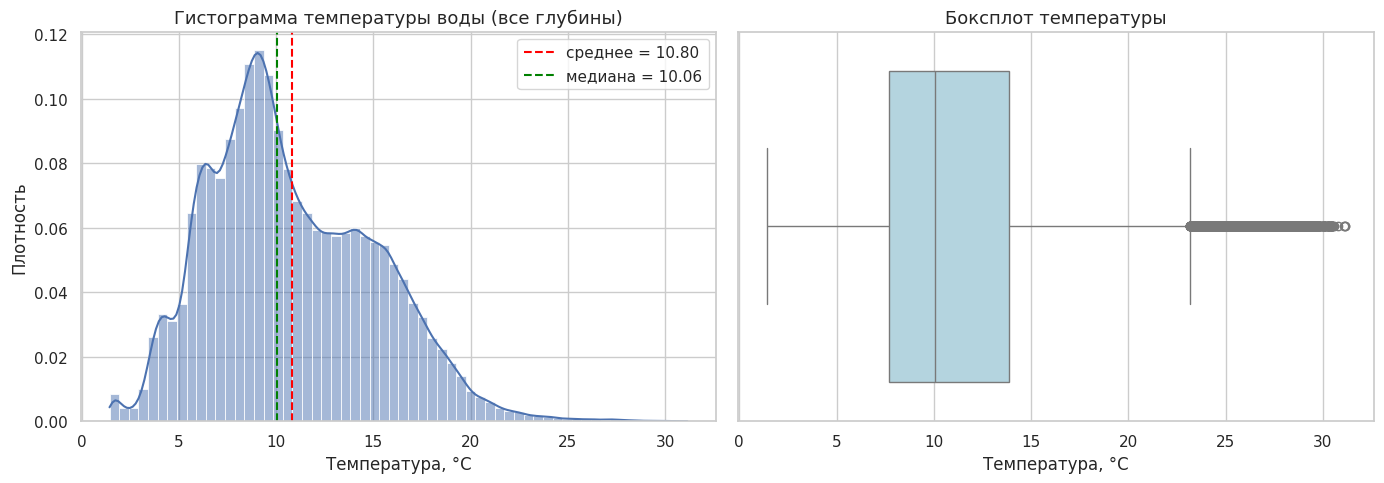

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(temp, bins=60, stat="density", kde=True, ax=ax[0])
ax[0].axvline(temp.mean(), color="red", ls="--", label=f"среднее = {temp.mean():.2f}")
ax[0].axvline(temp.median(), color="green", ls="--", label=f"медиана = {temp.median():.2f}")
ax[0].set_title("Гистограмма температуры воды (все глубины)")
ax[0].set_xlabel("Температура, °C"); ax[0].set_ylabel("Плотность")
ax[0].legend()

sns.boxplot(x=temp, ax=ax[1], color="lightblue")
ax[1].set_title("Боксплот температуры")
ax[1].set_xlabel("Температура, °C")
plt.tight_layout(); plt.show()

Выбросы ищем по правилу 1,5×IQR. Если $Q_1$ и $Q_3$ — первый и третий квартили, $IQR = Q_3 - Q_1$, то выбросами считаем значения вне интервала

$$[\,Q_1 - 1.5\cdot IQR,\; Q_3 + 1.5\cdot IQR\,].$$

In [28]:
q1, q3 = temp.quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = temp[(temp < low) | (temp > high)]

print(f"Q1 = {q1:.2f}, Q3 = {q3:.2f}, IQR = {iqr:.2f}")
print(f"Границы без выбросов: [{low:.2f}, {high:.2f}]")
print(f"Выбросов: {len(outliers)} ({100 * len(outliers) / N:.3f}% данных)")
if len(outliers):
    print(f"Выбросы лежат в диапазоне {outliers.min():.2f} ... {outliers.max():.2f} °C")

Q1 = 7.68, Q3 = 13.88, IQR = 6.20
Границы без выбросов: [-1.62, 23.18]
Выбросов: 3738 (0.438% данных)
Выбросы лежат в диапазоне 23.19 ... 31.14 °C


Выбросы по формуле я **не удаляю**: это реальные измерения (например, тёплая поверхность в тёплый сезон), а не ошибки прибора. Из физики понятно, что температура воды в океане в таком диапазоне — это нормально. Удалять такие точки значило бы искажать генеральную совокупность.

Распределение по всем глубинам смешанное: холодная глубокая вода и тёплая поверхностная дают разные «горбы», поэтому форма гистограммы может быть не колоколом. Это важно для выбора распределения ниже.

### Normalization

Два способа нормализации:

**Min-max** — приводит значения к отрезку $[0, 1]$:
$$x' = \frac{x - x_{min}}{x_{max} - x_{min}}$$

**Z-преобразование (стандартизация)** — среднее 0, стд. отклонение 1:
$$z = \frac{x - \bar x}{s}$$

Z-преобразование нужно, чтобы сравнивать величины в разных единицах и приводить нормальное распределение к стандартному $N(0,1)$. Форма распределения при обоих преобразованиях не меняется — меняются только масштаб и сдвиг.

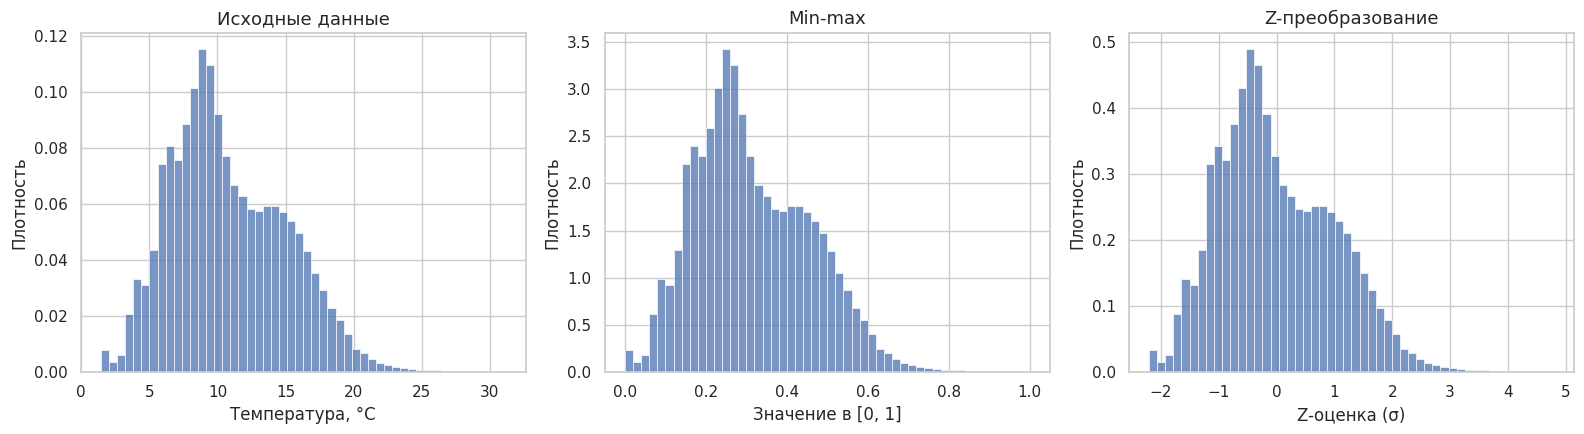

,исходные,min-max,z-score
min,1.4400,0.0000,-2.2055
max,31.1400,1.0000,4.7929
mean,10.7997,0.3151,0.0000
std,4.2438,0.1429,1.0000
skew,0.4886,0.4886,0.4886


In [29]:
temp_minmax = (temp - temp.min()) / (temp.max() - temp.min())
temp_z = (temp - temp.mean()) / temp.std(ddof=1)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, data, title, xl in zip(
        ax, [temp, temp_minmax, temp_z],
        ["Исходные данные", "Min-max", "Z-преобразование"],
        ["Температура, °C", "Значение в [0, 1]", "Z-оценка (σ)"]):
    sns.histplot(data, bins=50, stat="density", ax=a)
    a.set_title(title); a.set_xlabel(xl); a.set_ylabel("Плотность")
plt.tight_layout(); plt.show()

check = pd.DataFrame({
    "исходные": [temp.min(), temp.max(), temp.mean(), temp.std(), stats.skew(temp)],
    "min-max":  [temp_minmax.min(), temp_minmax.max(), temp_minmax.mean(), temp_minmax.std(), stats.skew(temp_minmax)],
    "z-score":  [temp_z.min(), temp_z.max(), temp_z.mean(), temp_z.std(), stats.skew(temp_z)],
}, index=["min", "max", "mean", "std", "skew"]).round(4)
check

Проверка: после min-max минимум = 0, максимум = 1; после Z-преобразования среднее ≈ 0 и стд = 1. Асимметрия во всех трёх колонках одинаковая — подтверждает, что форма распределения не изменилась.

### Independence & Estimations

Независимость проверять не нужно: в этой работе я анализирую одну величину, а не две величины одной природы.

#### Состоятельность оценок

Оценка $\hat\theta_n$ называется **состоятельной**, если она сходится по вероятности к истинному значению параметра при росте объёма выборки:
$$\forall \varepsilon>0:\quad P\big(|\hat\theta_n - \theta| > \varepsilon\big)\to 0,\quad n\to\infty.$$

Проверяем эмпирически для среднего $\bar x$ и выборочной дисперсии $s^2$ (с поправкой Бесселя, $n-1$). За «истинные» значения принимаем $\mu$ и $\sigma^2$ по всей генеральной совокупности.

Для каждого размера выборки $n$ делаем 30 повторных выборок, чтобы увидеть не одну случайную реализацию, а коридор разброса.

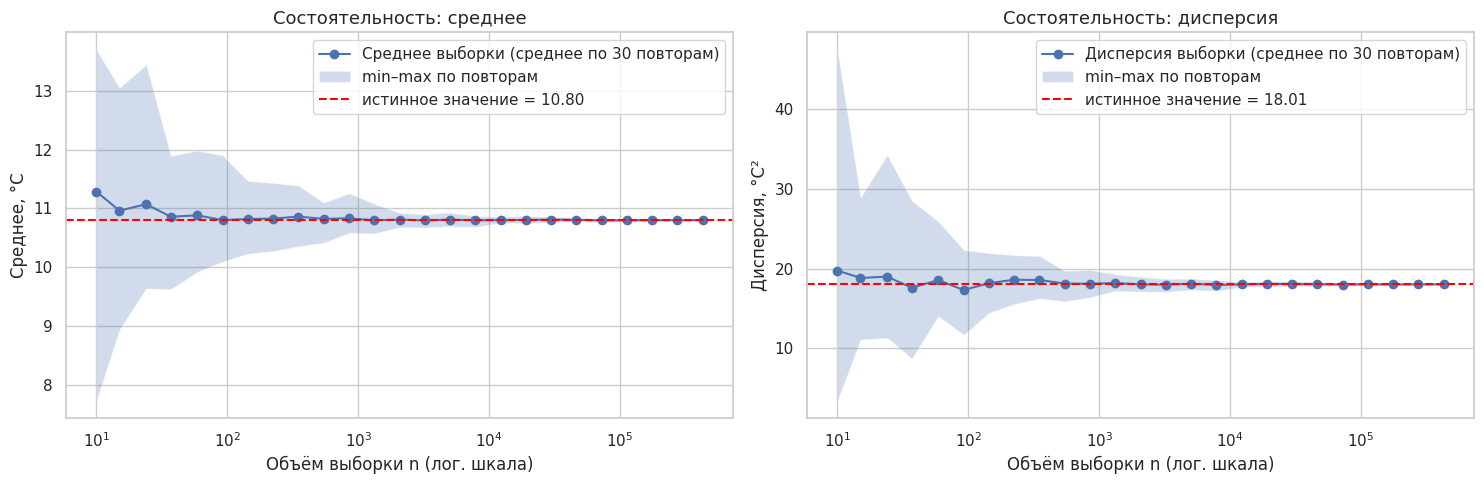

In [30]:
arr = temp.values
mu_true = arr.mean()
var_true = arr.var(ddof=1)

sizes = np.unique(np.logspace(1, np.log10(N // 2), 25).astype(int))
REPS = 30

mean_res = np.zeros((len(sizes), REPS))
var_res = np.zeros((len(sizes), REPS))
for i, n in enumerate(sizes):
    for r in range(REPS):
        s = rng.choice(arr, size=n, replace=False)
        mean_res[i, r] = s.mean()
        var_res[i, r] = s.var(ddof=1)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for a, res, true, name in zip(ax, [mean_res, var_res], [mu_true, var_true], ["Среднее", "Дисперсия"]):
    a.plot(sizes, res.mean(axis=1), marker="o", label=f"{name} выборки (среднее по {REPS} повторам)")
    a.fill_between(sizes, res.min(axis=1), res.max(axis=1), alpha=0.25, label="min–max по повторам")
    a.axhline(true, color="red", ls="--", label=f"истинное значение = {true:.2f}")
    a.set_xscale("log"); a.set_xlabel("Объём выборки n (лог. шкала)")
    a.set_title(f"Состоятельность: {name.lower()}")
    a.legend()
ax[0].set_ylabel("Среднее, °C"); ax[1].set_ylabel("Дисперсия, °C²")
plt.tight_layout(); plt.show()

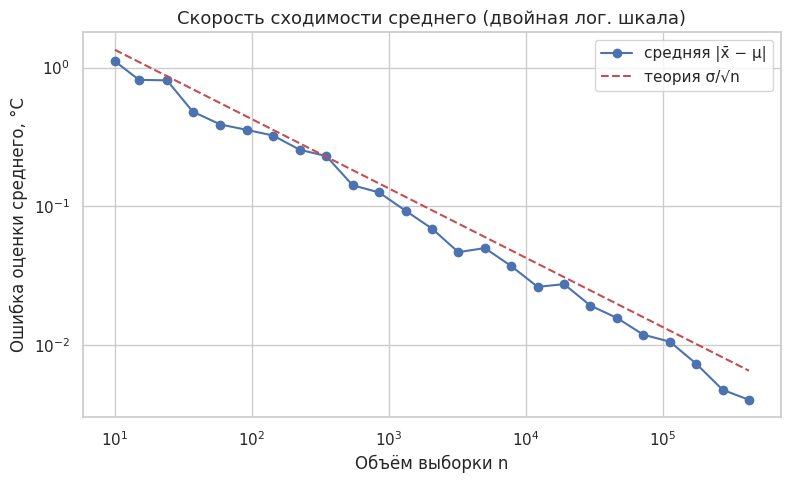

In [31]:
err_mean = np.abs(mean_res - mu_true).mean(axis=1)
plt.loglog(sizes, err_mean, marker="o", label="средняя |x̄ − μ|")
plt.loglog(sizes, np.sqrt(var_true) / np.sqrt(sizes), "r--", label="теория σ/√n")
plt.xlabel("Объём выборки n"); plt.ylabel("Ошибка оценки среднего, °C")
plt.title("Скорость сходимости среднего (двойная лог. шкала)")
plt.legend(); plt.show()

**Вывод.** С ростом $n$ коридор разброса сужается, а среднее и дисперсия выборки приближаются к истинным значениям (красная линия): обе оценки состоятельны. Ошибка среднего убывает примерно как $\sigma/\sqrt{n}$ (линии на лог-лог графике идут почти параллельно), что согласуется с законом больших чисел и ЦПТ. При малых $n$ (около 10) оценки сильно «скачут».

### Sampling: с возвращением и без возвращения

**С возвращением**: каждый элемент после выбора кладётся обратно, выбор независимый, один элемент может попасть в выборку несколько раз. Дисперсия выборочного среднего: $\mathrm{Var}(\bar x)=\dfrac{\sigma^2}{n}$.

**Без возвращения**: элемент выбирается один раз, выбор слегка зависимый. Дисперсия среднего меньше за счёт поправки на конечную совокупность (FPC):
$$\mathrm{Var}(\bar x)=\frac{\sigma^2}{n}\cdot\frac{N-n}{N-1}.$$

Когда $n \ll N$, поправка почти равна 1 и разницы практически нет. Её видно, когда $n$ сравнимо с $N$.

In [32]:
n = 5000

samp_with = rng.choice(arr, size=n, replace=True)
samp_without = rng.choice(arr, size=n, replace=False)

def stat_row(x, ddof=1):
    return {"n": len(x), "mean": np.mean(x), "median": np.median(x), "var": np.var(x, ddof=ddof),
            "std": np.std(x, ddof=ddof), "min": np.min(x), "max": np.max(x), "skew": stats.skew(x)}

table = pd.DataFrame({
    "генеральная (все данные)": stat_row(arr),
    "с возвращением": stat_row(samp_with),
    "без возвращения": stat_row(samp_without),
}).T.round(3)
table

,n,mean,median,var,std,min,max,skew
генеральная (все данные),853900.0,10.800,10.06,18.010,4.244,1.44,31.14,0.489
с возвращением,5000.0,10.929,10.16,18.063,4.250,1.49,30.06,0.441
без возвращения,5000.0,10.798,10.08,17.852,4.225,1.50,28.06,0.447


In [33]:
rel = table.loc[["с возвращением", "без возвращения"], ["mean", "median", "var", "std"]]
rel = (rel - table.loc["генеральная (все данные)", ["mean", "median", "var", "std"]]).abs() \
      / table.loc["генеральная (все данные)", ["mean", "median", "var", "std"]] * 100
print("Относительное отклонение от генеральной совокупности, %:")
rel.round(3)

Относительное отклонение от генеральной совокупности, %:


,mean,median,var,std
с возвращением,1.194,0.994,0.294,0.141
без возвращения,0.019,0.199,0.877,0.448


При $n = 5000$ из почти миллиона измерений обе выборки дают статистики, очень близкие к генеральным (отклонения — доли процента). Отличия между способами выбора на таком $n$ практически не видны, потому что $n \ll N$.

Чтобы показать разницу между способами, возьмём **маленькую «генеральную совокупность»** (2000 значений) и выборки размером $n=1500$, т. е. три четверти совокупности. Повторим процедуру много раз и посмотрим на разброс выборочных средних.

Среднее генеральной (малой) совокупности: 10.851


,Var(x̄) по эксперименту,Var(x̄) по теории
с возвращением,0.012003,0.011876
без возвращения,0.003091,0.002971


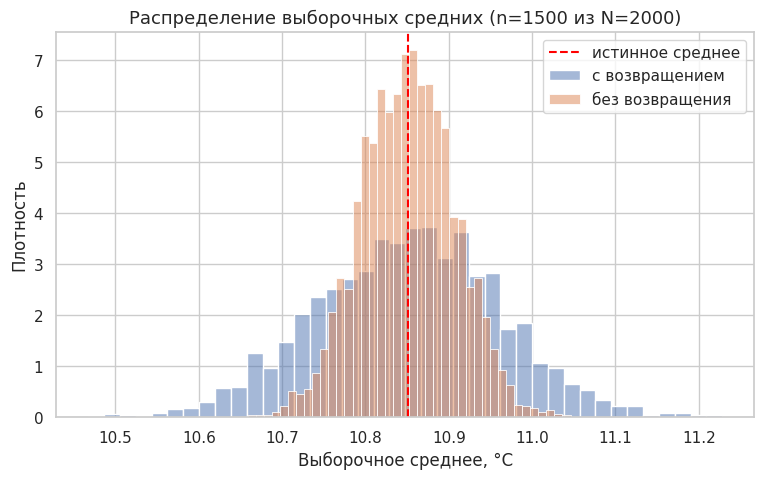

In [34]:
pop = rng.choice(arr, size=2000, replace=False)
N_small, n_small, B = len(pop), 1500, 3000

means_with = np.array([rng.choice(pop, n_small, replace=True).mean() for _ in range(B)])
means_without = np.array([rng.choice(pop, n_small, replace=False).mean() for _ in range(B)])

sigma2 = pop.var(ddof=0)
theory_with = sigma2 / n_small
theory_without = sigma2 / n_small * (N_small - n_small) / (N_small - 1)

res = pd.DataFrame({
    "Var(x̄) по эксперименту": [means_with.var(), means_without.var()],
    "Var(x̄) по теории": [theory_with, theory_without],
}, index=["с возвращением", "без возвращения"])
print(f"Среднее генеральной (малой) совокупности: {pop.mean():.3f}")
display(res.round(6))

sns.histplot(means_with, bins=40, stat="density", color="C0", alpha=0.5, label="с возвращением")
sns.histplot(means_without, bins=40, stat="density", color="C1", alpha=0.5, label="без возвращения")
plt.axvline(pop.mean(), color="red", ls="--", label="истинное среднее")
plt.xlabel("Выборочное среднее, °C"); plt.ylabel("Плотность")
plt.title(f"Распределение выборочных средних (n={n_small} из N={N_small})")
plt.legend(); plt.show()

**Вывод.** Обе схемы дают несмещённую оценку среднего (центр гистограмм совпадает с истинным средним). Но у выборки **без возвращения** разброс средних заметно меньше — как раз в $\frac{N-n}{N-1}$ раз, и эксперимент совпадает с теорией. Логично: если вытащить почти всю совокупность, то среднее выборки почти равно среднему совокупности. С возвращением же элементы повторяются, и информации в выборке меньше. Когда выборка малая относительно совокупности, оба способа дают практически одно и то же.

### Distribution: математическое описание

Подберём теоретическое распределение, которое лучше всего описывает температуру. Рассмотрим нормальное, логнормальное, гамма и Вейбулла (последние три определены только для положительных значений) и сравним их через:
- **критерий Колмогорова–Смирнова** $D = \sup_x |F_n(x) - F(x)|$ (чем меньше, тем лучше);
- **критерий Акаике** $AIC = 2k - 2\ln L$, где $k$ — число параметров, $L$ — максимум правдоподобия (чем меньше, тем лучше).

Параметры подбираются методом максимального правдоподобия (MLE). Для скорости используем случайную подвыборку из 20 000 значений.

In [35]:
fit_data = rng.choice(arr, size=20000, replace=False)
positive = fit_data.min() > 0
print("Все значения > 0:", positive)

candidates = {"norm": stats.norm, "skewnorm": stats.skewnorm}
if positive:
    candidates.update({"lognorm": stats.lognorm, "gamma": stats.gamma, "weibull_min": stats.weibull_min})

rows, fitted = [], {}
for name, dist in candidates.items():
    params = dist.fit(fit_data)
    ll = np.sum(dist.logpdf(fit_data, *params))
    k = len(params)
    ks = stats.kstest(fit_data, dist.cdf, args=params).statistic
    rows.append({"распределение": name, "параметры": np.round(params, 3), "KS D": ks, "AIC": 2 * k - 2 * ll})
    fitted[name] = params

fit_table = pd.DataFrame(rows).sort_values("AIC").reset_index(drop=True)
fit_table

Все значения > 0: True


,распределение,параметры,KS D,AIC
0,skewnorm,"[3.107, 5.742, 6.584]",0.032988,113280.377300
1,gamma,"[9.179, -2.168, 1.41]",0.032487,113365.898156
2,weibull_min,"[2.412, 1.168, 10.845]",0.042704,113418.808280
3,lognorm,"[0.224, -8.096, 18.408]",0.034744,113433.320711
4,norm,"[10.778, 4.241]",0.071462,114555.299109


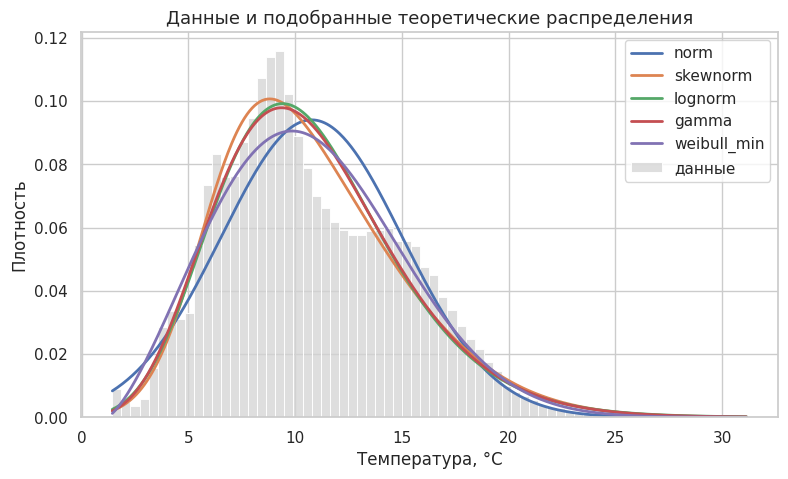

In [17]:
xs = np.linspace(arr.min(), arr.max(), 500)
sns.histplot(arr, bins=70, stat="density", color="lightgray", label="данные")
for name, params in fitted.items():
    plt.plot(xs, candidates[name].pdf(xs, *params), lw=2, label=name)
plt.xlabel("Температура, °C"); plt.ylabel("Плотность")
plt.title("Данные и подобранные теоретические распределения")
plt.legend(); plt.show()

**Нормальное распределение** $N(\mu,\sigma^2)$ — базовый вариант:

$$f(x)=\frac{1}{\sigma\sqrt{2\pi}}\exp\left(-\frac{(x-\mu)^2}{2\sigma^2}\right),\quad x\in\mathbb R$$

$E[X]=\mu,\; D[X]=\sigma^2$, симметрично относительно $\mu$, асимметрия 0, эксцесс 0. Если $X \sim N(\mu,\sigma^2)$, то $Z=\frac{X-\mu}{\sigma}\sim N(0,1)$. Оценки MLE: $\hat\mu=\bar x$, $\hat\sigma^2=\frac1n\sum(x_i-\bar x)^2$.

**Гамма-распределение** $\Gamma(k,\theta)$ (подходит для положительных величин с правым хвостом):

$$f(x)=\frac{x^{k-1}e^{-x/\theta}}{\Gamma(k)\,\theta^{k}},\quad x>0$$

$E[X]=k\theta,\; D[X]=k\theta^2$, асимметрия $2/\sqrt k$.

**Логнормальное** (если $\ln X\sim N(\mu,\sigma^2)$):
$$f(x)=\frac{1}{x\sigma\sqrt{2\pi}}\exp\left(-\frac{(\ln x-\mu)^2}{2\sigma^2}\right),\quad x>0.$$

> **Что вписать после запуска:** какое распределение оказалось лучшим по AIC / KS (первая строка `fit_table`), какие у него параметры и совпадает ли оно визуально с гистограммой. Если ни одно не подходит хорошо (а для температуры по всем глубинам это вполне возможно — данные смешанные: тёплая поверхность + холодная глубина), так и напиши: распределение мультимодальное, это смесь нескольких нормальных, и лучше описывать его по срезам глубин. Дальше есть проверка на срезе.

### Hypothesis testing

**Гипотеза 1 (о виде распределения).**
$H_0$: температура воды (все глубины) распределена нормально. $H_1$: не нормально. Уровень значимости $\alpha = 0.05$.

Нюанс: при очень больших выборках (сотни тысяч) любой тест «видит» даже мельчайшие отклонения от нормальности и почти всегда отвергает $H_0$. Поэтому тесты делаем на подвыборке 5000 и дополнительно смотрим Q–Q график.

,статистика,p-value,решение при α=0.05
Shapiro-Wilk,0.979666,3.521288e-26,отвергаем H0
D'Agostino-Pearson,173.838655,1.784085e-38,отвергаем H0
Kolmogorov-Smirnov,0.074754,9.567751e-25,отвергаем H0


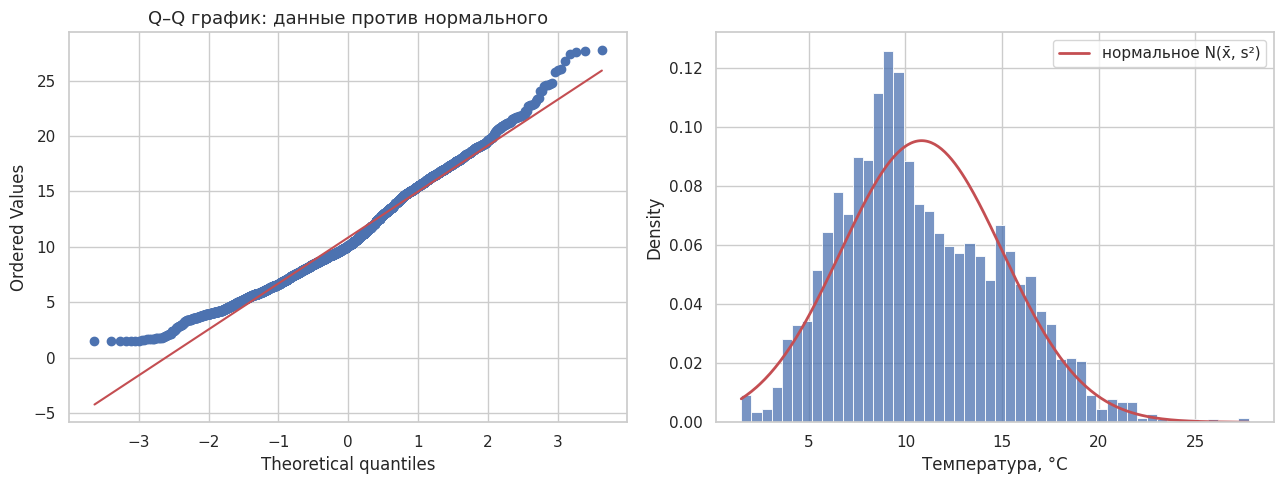

In [36]:
alpha = 0.05
test_sample = rng.choice(arr, size=5000, replace=False)

# 1) Шапиро-Уилк
sh_stat, sh_p = stats.shapiro(test_sample)
# 2) Д'Агостино-Пирсон (по асимметрии и эксцессу)
da_stat, da_p = stats.normaltest(test_sample)
# 3) Колмогоров-Смирнов с оценёнными параметрами (p-value приближённый, т.к. параметры оценены по этим же данным)
ks_stat, ks_p = stats.kstest(test_sample, "norm", args=(test_sample.mean(), test_sample.std(ddof=1)))

res = pd.DataFrame({"статистика": [sh_stat, da_stat, ks_stat], "p-value": [sh_p, da_p, ks_p]},
                   index=["Shapiro-Wilk", "D'Agostino-Pearson", "Kolmogorov-Smirnov"])
res["решение при α=0.05"] = np.where(res["p-value"] < alpha, "отвергаем H0", "не отвергаем H0")
display(res)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
stats.probplot(test_sample, dist="norm", plot=ax[0])
ax[0].set_title("Q–Q график: данные против нормального")
sns.histplot(test_sample, bins=50, stat="density", ax=ax[1])
xx = np.linspace(test_sample.min(), test_sample.max(), 300)
ax[1].plot(xx, stats.norm.pdf(xx, test_sample.mean(), test_sample.std(ddof=1)), "r", lw=2, label="нормальное N(x̄, s²)")
ax[1].set_xlabel("Температура, °C"); ax[1].legend()
plt.tight_layout(); plt.show()

**Гипотеза 2 (о нормальности на срезе).**
Температура зависит от глубины, поэтому на фиксированной глубине распределение может быть проще. Проверяем $H_0$: температура на поверхности ($0$ м) нормальна.

Измерений на поверхности: 32344
Shapiro-Wilk:        W = 0.9683, p = 7.53e-32
D'Agostino-Pearson:  stat = 573.59, p = 2.79e-125
skew = 0.775, excess kurtosis = 1.413


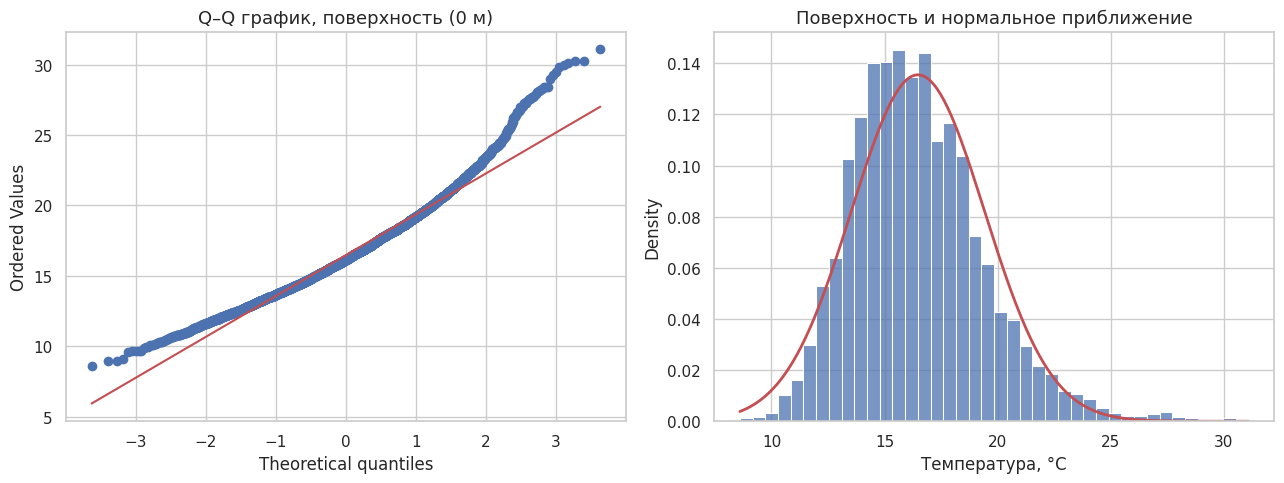

In [19]:
surf = surface.values
print(f"Измерений на поверхности: {len(surf)}")
surf_test = rng.choice(surf, size=min(5000, len(surf)), replace=False)

sh_stat, sh_p = stats.shapiro(surf_test)
da_stat, da_p = stats.normaltest(surf_test)
print(f"Shapiro-Wilk:        W = {sh_stat:.4f}, p = {sh_p:.3g}")
print(f"D'Agostino-Pearson:  stat = {da_stat:.2f}, p = {da_p:.3g}")
print(f"skew = {stats.skew(surf):.3f}, excess kurtosis = {stats.kurtosis(surf):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
stats.probplot(surf_test, dist="norm", plot=ax[0]); ax[0].set_title("Q–Q график, поверхность (0 м)")
sns.histplot(surf_test, bins=40, stat="density", ax=ax[1])
xx = np.linspace(surf_test.min(), surf_test.max(), 300)
ax[1].plot(xx, stats.norm.pdf(xx, surf_test.mean(), surf_test.std(ddof=1)), "r", lw=2)
ax[1].set_xlabel("Температура, °C"); ax[1].set_title("Поверхность и нормальное приближение")
plt.tight_layout(); plt.show()

**Гипотеза 3 (о средних на разных глубинах).**
$H_0$: средняя температура на поверхности (0 м) и на глубине 500 м одинакова. $H_1$: различается. Используем t-критерий Уэлча (не требует равенства дисперсий) и непараметрический критерий Манна–Уитни (не требует нормальности).

In [20]:
deep = df.loc[df["Depthm"] == 500, "T_degC"].dropna().values
print(f"Измерений на 500 м: {len(deep)}; среднее = {deep.mean():.2f} °C; на поверхности: {surf.mean():.2f} °C")

t_stat, t_p = stats.ttest_ind(surf, deep, equal_var=False)
u_stat, u_p = stats.mannwhitneyu(surf, deep, alternative="two-sided")
print(f"Welch t-test:  t = {t_stat:.2f}, p = {t_p:.3g}")
print(f"Mann-Whitney:  U = {u_stat:.0f}, p = {u_p:.3g}")

# доверительный интервал для разности средних (приближённо, нормальная аппроксимация)
diff = surf.mean() - deep.mean()
se = np.sqrt(surf.var(ddof=1) / len(surf) + deep.var(ddof=1) / len(deep))
print(f"Разность средних = {diff:.2f} °C, 95% ДИ ≈ [{diff - 1.96*se:.2f}, {diff + 1.96*se:.2f}]")

Измерений на 500 м: 24663; среднее = 6.15 °C; на поверхности: 16.47 °C
Welch t-test:  t = 611.45, p = 0
Mann-Whitney:  U = 797634495, p = 0
Разность средних = 10.32 °C, 95% ДИ ≈ [10.28, 10.35]


> **Как интерпретировать (дописать по результатам запуска):**
> - Если $p < 0.05$ — $H_0$ отвергаем (данные противоречат гипотезе). Если $p \ge 0.05$ — $H_0$ не отвергаем (но это не доказательство, что она верна, мы лишь не нашли противоречий).
> - Для гипотезы 3 ожидаемо $p \approx 0$: поверхность и глубина 500 м сильно отличаются по температуре.

### Выводы (Random Variable 01 — температура воды)

*Числа в `<>` нужно заменить значениями из твоих расчётов выше.*

1. **Случайность.** Температура воды — случайная величина. Даже при фиксированной глубине (0 м) значения сильно различаются (от <min> до <max> °C), а модель «температура = функция(глубина)» объясняет лишь долю $R^2=<значение>$ изменчивости. Остальное — влияние сезона, места, течений и ошибок прибора, которые заранее не посчитать.

2. **EDA.** Среднее = <mean> °C, медиана = <median> °C, стд. отклонение = <std> °C. Асимметрия = <skew>, эксцесс = <kurt>. По правилу 1,5×IQR найдено <число> выбросов (<процент>%). Я их не удалял: это реальные физические измерения. Форма распределения <одногорбая / многогорбая>, это объясняется <разной глубиной: холодная глубокая и тёплая поверхностная вода>.

3. **Нормализация.** Min-max переводит данные в [0, 1], Z-преобразование даёт среднее 0 и стд 1. Форма распределения (асимметрия) не меняется — меняется только шкала.

4. **Состоятельность.** Выборочные среднее и дисперсия сходятся к истинным значениям при росте $n$, коридор разброса сужается, ошибка среднего убывает примерно как $\sigma/\sqrt n$. Оценки состоятельны.

5. **Выборки.** При $n \ll N$ выборки с возвращением и без возвращения практически одинаково хорошо описывают генеральную совокупность (отклонения статистик <значение>%). Разница проявляется при $n$, сравнимом с $N$: без возвращения дисперсия среднего меньше в $\frac{N-n}{N-1}$ раз, что подтвердилось экспериментом.

6. **Распределение.** По AIC и KS лучшим из рассмотренных оказалось <название> с параметрами <параметры>. <Совпадает ли оно с гистограммой? Если нет — причина в смешанной природе данных (разные глубины).>

7. **Гипотезы.** Гипотеза о нормальности по всем глубинам <отвергнута/не отвергнута> ($p=<значение>$). На срезе поверхности (0 м) нормальность <отвергнута/не отвергнута> ($p=<значение>$). Гипотеза о равенстве средних на 0 м и 500 м отвергнута ($p<значение>$), разность ≈ <значение> °C. Интерпретация для датасета: температура в океане определяется прежде всего глубиной, поэтому единое распределение «для всего океана» неудобно, лучше описывать температуру по слоям глубины.

8. **Что можно улучшить.** Добавить анализ по сезонам и годам (влияние Эль-Ниньо), рассмотреть смесь нормальных распределений, сравнить с готовыми разборами датасета (после выполнения своей работы) и подтвердить/опровергнуть свои выводы.

## Lab resume

### cat_mark_table

| cat_id | notebook_link | coeff | comment |
|--------|---------------|-------|---------|
| описание природы величины | [Description](#description-природа-события) | | описана физическая природа измерений CalCOFI |
| доказательство случайности | [Proof of randomness](#proof-of-randomness-почему-это-случайная-величина) | | срез на одной глубине + модель T=f(depth), R² < 1 |
| EDA | [EDA & Distribution](#eda--distribution) | | describe, гистограмма, боксплот, выбросы 1.5×IQR |
| нормализация | [Normalization](#normalization) | | min-max и Z-преобразование |
| состоятельность оценок | [Independence & Estimations](#independence--estimations) | | среднее и дисперсия, скорость сходимости σ/√n |
| выборка с возвр. / без | [Sampling](#sampling-с-возвращением-и-без-возвращения) | | сравнение со статистиками генеральной, FPC |
| мат. описание распределения | [Distribution](#distribution-математическое-описание) | | формулы, MLE, AIC и KS |
| проверка гипотез | [Hypothesis testing](#hypothesis-testing) | | 3 гипотезы: нормальность (все данные и срез), равенство средних |
| выводы | [Выводы](#выводы-random-variable-01--температура-воды) | | своими словами |

*Колонку `coeff` заполняет преподаватель/автор по критериям.*